In [2]:
import torch 
import torch.nn as nn

In [3]:
class DepthBasedNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.encoder_layer=nn.Sequential(

            nn.Conv2d(3,16,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.Conv2d(16,32,kernel_size=3,padding=1),
            nn.ReLU()
        )

        self.decoder_layer=nn.Sequential(
            nn.Conv2d(32,16,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.Conv2d(16,1,kernel_size=3,padding=1)        
        )

    def forward(self,x):
        features=self.encoder_layer(x)
        output=self.decoder_layer(features)
        return output
    


In [4]:
image=torch.randn(1,3,64,64)

In [5]:
model=DepthBasedNN()
depth=model(image)
print(depth.shape)

torch.Size([1, 1, 64, 64])


In [6]:
ex1_image=torch.rand(100,1,16,16)

bright='close'
dark='far'

Backup_image=ex1_image.clone()


In [7]:
class TinyDepthNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(16, 1, 3, padding=1)
        )

    def forward(self, x):
        return self.net(x)


model = TinyDepthNet()

In [8]:
import torch.optim as optim
loss_function = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [9]:
for epoch in range(100):

    prediction = model(ex1_image)

    loss = loss_function(prediction, Backup_image)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    if epoch % 10 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.6f}")

Epoch 0, Loss: 0.351155
Epoch 10, Loss: 0.106637
Epoch 20, Loss: 0.101263
Epoch 30, Loss: 0.084195
Epoch 40, Loss: 0.073717
Epoch 50, Loss: 0.066365
Epoch 60, Loss: 0.057820
Epoch 70, Loss: 0.049187
Epoch 80, Loss: 0.040887
Epoch 90, Loss: 0.033419


In [10]:
test_image=torch.rand(1,1,16,16)

with torch.no_grad():
    depth_pred=model(test_image)
print(depth_pred.shape)

torch.Size([1, 1, 16, 16])


In [11]:
import torch

import matplotlib.pyplot as plt

from PIL import Image

from transformers import AutoImageProcessor, AutoModelForDepthEstimation



model_name = "depth-anything/Depth-Anything-V2-Small-hf"



processor = AutoImageProcessor.from_pretrained(model_name)

model = AutoModelForDepthEstimation.from_pretrained(model_name)



/home/prashanna/miniforge3/envs/rl/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 287/287 [00:00<00:00, 2571.36it/s]


In [12]:
param_size=sum(p.numel() for p in model.parameters())
train_param_size=sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {param_size}")
print(f"Trainable parameters: {train_param_size}")

Total parameters: 24785089
Trainable parameters: 24785089


In [13]:
image=Image.open("/home/prashanna/Documents/PROJECT VBMD/pic.jpeg").convert("RGB")
inputs=processor(images=[image],return_tensors="pt")


In [14]:
with torch.no_grad():
    outputs=model(**inputs)
predicted_depth=outputs.predicted_depth
   

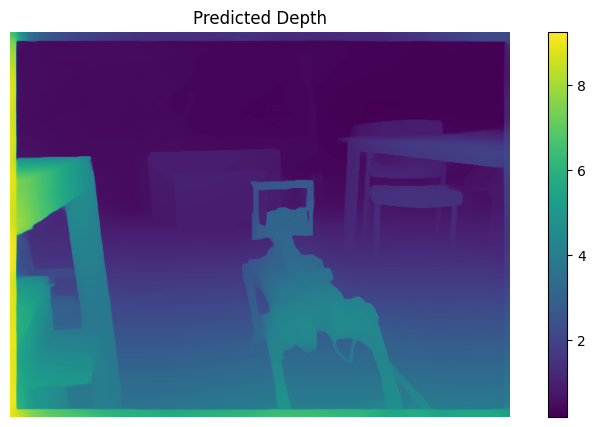

In [15]:
depth = predicted_depth.squeeze().cpu().numpy()

plt.figure(figsize=(10, 5))

plt.imshow(depth)
plt.colorbar()

plt.title("Predicted Depth")
plt.axis("off")

plt.show()